# Single-turbine fault prediction: 2018–2025
This is the main walkthrough for **turbine 2304510**. It uses **target A only**: recorded daily fault time. It includes processing, classifiers, reference rules, validation, evaluation, figures, and saved results.

**How to use:** select your project's Python kernel at the top right, then choose **Run All**. Run cells from top to bottom. Dependencies are installed from the repository root with `python -m pip install -r docs/general/requirements.txt`. The first raw-data run can take several minutes; later runs reuse verified annual caches.

| Section | What happens | Years |
|---|---|---|
| 1. Data processing | Read this turbine, clean, build daily features and fault labels | 2018–2025 |
| 2. Training | Fit feature preprocessing, logistic regression, random forest and sensor reference | 2018–2021 |
| 3. Validation | Choose alert thresholds using a false-alarm budget | 2022 |
| 4. Evaluation | Freeze everything and score unseen days; inspect metrics and plots | 2023–2025 |

Test years are **not** used to fit classifiers. This is a chronological holdout experiment, not shuffled cross-validation. Each section displays intermediate tables so you can see what is happening.

In [1]:
from pathlib import Path
import json
import sys
import warnings

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

from wt_predmaint.config import load_protocol
from wt_predmaint.data.single_turbine_pipeline import experiment_config, prepare
from wt_predmaint.features.daily import KEYS, feature_columns
from wt_predmaint.models.single_year import fit_classifier, risk_scores
from wt_predmaint.models.baselines import sensor_rule_fit, sensor_rule_score, daily_metrics
from wt_predmaint.evaluation.metrics import evaluate, detect_episodes, threshold_for_budget

%matplotlib inline
pd.set_option("display.max_columns", 20)
print("Repository:", ROOT)
print("Python kernel:", sys.executable)

Repository: C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7
Python kernel: C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7\.venv\Scripts\python.exe


## Experiment settings
Change the turbine or years here, then rerun the notebook from the top. Keep training, validation, and testing separate. The shared project protocol is copied, not edited.

Results from this notebook have their own **target_a_notebook/** subfolder. Existing script-generated results are kept separate.

In [2]:
STATION = 2304510
START_YEAR, TRAIN_END, VALIDATION_YEAR, END_YEAR = 2018, 2021, 2022, 2025
MAX_MISSING = 0.8
REBUILD_RAW_CACHE = False

cfg = experiment_config(load_protocol(), START_YEAR, TRAIN_END, VALIDATION_YEAR, END_YEAR)
SEED = int(cfg["seed"])
scope = f"{START_YEAR}_{END_YEAR}/turbine_{STATION}"
PREPARED = ROOT / "data/interim/multi_year" / scope
RESULTS = ROOT / "data/processed/multi_year" / scope / "target_a_notebook"
FIGURES = ROOT / "reports/figures/multi_year" / scope / "target_a_notebook"
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

display(pd.DataFrame([
    {"purpose": name, "years": years}
    for name, years in cfg["splits"].items()
]))
print("Notebook data/results:", RESULTS)
print("Notebook figures:", FIGURES)

,purpose,years
0,train_years,"[2018, 2019, 2020, 2021]"
1,val_years,[2022]
2,test_years,"[2023, 2024, 2025]"


Notebook data/results: C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7\data\processed\multi_year\2018_2025\turbine_2304510\target_a_notebook
Notebook figures: C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7\reports\figures\multi_year\2018_2025\turbine_2304510\target_a_notebook


## 1. Data processing
### What counts as a fault?
A day is a fault day when the daily summary records **at least four hours in TimeErr**, using the configured rule. Related fault days are merged into one **episode**, with the configured seven-day gap rule.

The classifier asks: **will a new episode start in the next 30 days?** It does not predict an arbitrary alarm code or the exact fault date. A row describes what is known at the end of a turbine-day.

- **Positive (1):** an episode starts in the next 30 days.
- **Negative (0):** an eligible observed day without such an episode or an episode in the exclusion zone.
- Days within episodes, the 31–60-day exclusion zone, insufficient observation, and other unusable cases have no training label.
- The full **60-day label horizon** is purged at train/validation/test boundaries.

TimeErr is the project's fault-time proxy; its meaning has not been independently confirmed by a provider dictionary. The result predicts this recorded outcome, not a physically verified component failure.

### Read, filter and prepare
The helper below reads extracted raw CSVs in chunks, keeps only this turbine, applies the existing cleaning rules, builds trailing features, and creates **only target-A labels**. Annual source caches are reused when file metadata and preparation settings match. Entire missing sensor days are audited and excluded rather than filled with imaginary data.

In [3]:
prepare(
    raw=ROOT / "data/raw",
    output=PREPARED,
    station=STATION,
    cfg=cfg,
    rebuild=REBUILD_RAW_CACHE,
    targets=("a",),
)

features = pd.read_parquet(PREPARED / "features.parquet")
labels = pd.read_parquet(PREPARED / "a_labels.parquet")
episodes = pd.read_parquet(PREPARED / "a_episodes.parquet")
assert features["StationId"].eq(STATION).all()
assert labels["StationId"].eq(STATION).all()
assert episodes["StationId"].eq(STATION).all()

display(pd.read_csv(PREPARED / "label_summary.csv"))
display(features.head())
display(episodes.head())
display(labels["status"].value_counts().rename_axis("label_status").to_frame("days"))

2018: reuse verified station cache


2019: reuse verified station cache


2020: reuse verified station cache


2021: reuse verified station cache


2022: reuse verified station cache


...

2025: reuse verified station cache


,split,candidate_days,labelled_rows,positives,positive_rate,turbines_with_positives,episodes,n_negative,n_positive,n_in_episode,n_zone,n_purged,n_censored,n_low_coverage,target
0,train,1436,1077,378,0.3510,1,16,699,378,55,244,60,0,0,A
1,val,343,192,144,0.7500,1,6,48,144,36,65,50,0,0,A
2,test,1079,734,409,0.5572,1,16,325,409,51,273,0,21,0,A


,StationId,Day,n_intervals,frac_producing,frac_idle,frac_stopped,wind_mean,wind_std,rpm_mean,masked_frac,...,alarm_8236_w7,alarm_20_w7,alarm_25_w7,alarm_102_w7,alarm_tier1_w7,alarm_tier2_w7,alarm_tier3_w7,alarm_total_w7,days_since_fault_day,fault_days_30
0,2304510,2018-01-01,144.0,0.368056,0.000000,0.0,6.212481,1.339354,930.449646,0.0,...,0,10,10,0,0,0,20,20,NaN,0.0
1,2304510,2018-01-02,144.0,0.354167,0.000000,0.0,5.866343,2.650771,963.417542,0.0,...,0,24,25,0,0,0,49,49,NaN,0.0
2,2304510,2018-01-03,144.0,0.208333,0.347222,0.0,3.682209,2.718721,554.815796,0.0,...,0,30,31,0,1,0,61,62,NaN,0.0
3,2304510,2018-01-04,144.0,0.048611,0.208333,0.0,3.728638,1.968301,590.410156,0.0,...,0,44,45,0,1,0,89,90,NaN,0.0
4,2304510,2018-01-05,144.0,0.118056,0.000000,0.0,4.539466,1.651311,789.506653,0.0,...,0,114,114,0,2,0,228,230,NaN,0.0


,StationId,Start,End
0,2304510,2018-03-14,2018-03-17
1,2304510,2018-04-05,2018-04-10
2,2304510,2018-04-30,2018-04-30
3,2304510,2018-05-15,2018-05-15
4,2304510,2018-05-25,2018-05-26


,days
label_status,
negative,1072
positive,931
zone,582
in_episode,142
purged,110
censored,21
low_coverage,0


### Join inputs to labels and inspect the split
Keys are turbine ID and day. Neither key is a predictor. Rows without a future-event label are excluded. The table below makes missing feature rows and the class balance visible.

In [4]:
candidates = feature_columns(features)  # Select inputs before labels are joined.
joined = labels.merge(features, on=KEYS, how="left", validate="one_to_one", indicator=True)
support_rows = []
for split in ("train", "val", "test"):
    selected = joined["split"].eq(split) & joined["label"].notna()
    support_rows.append({
        "split": split,
        "labelled_days": int(selected.sum()),
        "days_without_features": int((selected & joined["_merge"].ne("both")).sum()),
    })
coverage = pd.DataFrame(support_rows)

data = joined.loc[joined["label"].notna() & joined["_merge"].eq("both")].copy()
data["label"] = data["label"].astype(int)
train, validation, test = [
    data.loc[data["split"].eq(s)].sort_values(KEYS).copy()
    for s in ("train", "val", "test")
]
assert all(not frame.empty for frame in (train, validation, test)), "A split has no data."
assert train["label"].nunique() == validation["label"].nunique() == 2, "Both classes are needed."
horizon = pd.Timedelta(days=int(cfg["labels"]["exclusion_end_days"]))
assert (train["Day"] + horizon < pd.Timestamp(f"{VALIDATION_YEAR}-01-01")).all()
assert (validation["Day"] + horizon < pd.Timestamp(f"{VALIDATION_YEAR + 1}-01-01")).all()
display(coverage)
display(pd.DataFrame([
    {"split": name, "days": len(frame), "first_day": frame["Day"].min(),
     "last_day": frame["Day"].max(), "positive_days": int(frame["label"].sum()),
     "negative_days": int(frame["label"].eq(0).sum()), "positive_share": frame["label"].mean()}
    for name, frame in (("train", train), ("validation", validation), ("test", test))
]))

,split,labelled_days,days_without_features
0,train,1077,0
1,val,192,0
2,test,734,0


,split,days,first_day,last_day,positive_days,negative_days,positive_share
0,train,1077,2018-01-01,2021-11-01,378,699,0.350975
1,validation,192,2022-01-01,2022-10-30,144,48,0.750000
2,test,734,2023-01-18,2025-11-27,409,325,0.557221


## 2. Training
### Inputs and classifiers
The inputs are daily producing-state sensor means, daily maxima, operating conditions, seven-day trends, selected alarm counts, and known fault history. Alarm counts are predictors; they do not define the outcome.

Feature selection uses **training rows only**: discard constant inputs and inputs more than 80% missing. Fit median imputation and standard scaling on training only. Date, turbine ID, labels, split/status, and quality metadata are not predictors.

We fit two classifiers:
- **Logistic regression:** weighted feature combinations, L2 regularisation, balanced classes.
- **Random forest:** 300 trees, depth at most 6, leaf size at least 10, balanced subsample weights.

There is no hyperparameter search. The scores are **not calibrated probabilities**.

In [5]:
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    logistic, columns, feature_audit = fit_classifier(train, candidates, SEED, MAX_MISSING)

forest = clone(logistic)
forest.set_params(classifier=RandomForestClassifier(
    n_estimators=300, max_depth=6, min_samples_leaf=10,
    class_weight="balanced_subsample", random_state=SEED, n_jobs=2,
))
forest.fit(train[columns].replace([np.inf, -np.inf], np.nan), train["label"])
models = {"logistic regression": logistic, "random forest": forest}

feature_audit["forest_importance"] = feature_audit["feature"].map(
    dict(zip(columns, forest[-1].feature_importances_, strict=True))
)
print(f"Used {len(columns)} of {len(candidates)} candidate features.")
display(feature_audit.loc[feature_audit["used"]].head(20))

Used 321 of 351 candidate features.


,feature,training_missing_share,training_unique_values,used,coefficient,forest_importance
0,frac_producing,0.000000,152,True,0.400430,0.000206
1,frac_idle,0.000000,77,True,0.125896,0.000273
2,frac_stopped,0.000000,28,True,0.299830,0.000000
3,wind_mean,0.000000,1077,True,-0.251403,0.000746
4,wind_std,0.000000,1077,True,0.142418,0.000429
5,rpm_mean,0.000000,1077,True,0.364023,0.001066
6,op_wtc_SecAnemo_mean,0.224698,835,True,0.125802,0.000273
7,op_wtc_YawPos_mean,0.224698,835,True,0.053702,0.000472
8,op_wtc_GenRpm_mean,0.224698,835,True,-0.013812,0.000244
9,op_wtc_MainSRpm_mean,0.224698,835,True,-0.014427,0.000275


### Simple references: do we beat an ordinary high-reading rule?
The sensor rule scores unusually high temperature/pressure readings relative to **training medians and interquartile ranges**. It is a relative outlier rule, not a manufacturer's safety limit. We also include constant and random scores. All comparisons will use exactly the same validation/test days.

In [6]:
rule = sensor_rule_fit(train, columns)
feature_audit["sensor_rule_used"] = feature_audit["feature"].isin(rule["features"])
rng = np.random.default_rng([SEED, STATION, 0])

def score_frame(frame):
    return {
        "logistic regression": risk_scores(logistic, frame, columns),
        "random forest": risk_scores(forest, frame, columns),
        "high sensor rule": sensor_rule_score(rule, frame),
        "constant (prevalence)": np.zeros(len(frame)),
        "random uniform": rng.uniform(size=len(frame)),
    }

def feature_group(name):
    if name.startswith(("w7mean_", "w7std_")): return "Seven-day trends"
    if name.startswith("op_"): return "Producing sensor means"
    if name.startswith("max_"): return "Daily sensor maxima"
    if name.startswith("alarm_"): return "Alarm history"
    if name in ("fault_days_30", "days_since_fault_day"): return "Known fault history"
    return "Operating conditions"

feature_audit["group"] = feature_audit["feature"].map(feature_group)
display(feature_audit.loc[feature_audit["used"]].groupby("group").size().to_frame("features_used"))
display(feature_audit.loc[feature_audit["sensor_rule_used"], ["feature", "training_missing_share"]])

,features_used
group,
Alarm history,11
Daily sensor maxima,35
Known fault history,2
Operating conditions,6
Producing sensor means,62
Seven-day trends,205


,feature,training_missing_share
27,op_wtc_A1ExtTmp_mean,0.224698
28,op_wtc_A3LefTmp_mean,0.224698
29,op_wtc_A3RigTmp_mean,0.224698
30,op_wtc_A9IntTmp_mean,0.224698
31,op_wtc_AmbieTmp_mean,0.224698
32,op_wtc_BrkTmpGn_mean,0.224698
33,op_wtc_Gen1U1Tm_mean,0.224698
34,op_wtc_Gen1V1Tm_mean,0.224698
35,op_wtc_Gen1W1Tm_mean,0.224698
36,op_wtc_GenBeGTm_mean,0.224698


## 3. Validation
### Choose the alert threshold using 2022
An alert occurs when **score > threshold**. We choose each threshold on validation data to stay within the configured budget of **one false alarm per turbine-month**. We then freeze it.

This is alert-threshold selection, not probability calibration. The threshold is not readjusted using test results. The validation metrics shown here are used for development and are not an unbiased final performance estimate.

In [7]:
validation_scores = score_frame(validation)
thresholds, validation_rows = {}, []
for name, scores in validation_scores.items():
    threshold = threshold_for_budget(
        validation["label"].to_numpy(), scores,
        float(cfg["evaluation"]["false_alarm_budget_per_turbine_month"]),
        float(cfg["evaluation"]["days_per_month"]),
    )
    thresholds[name] = threshold
    scored = validation[[*KEYS, "label"]].assign(score=scores)
    validation_rows.append({
        "model": name, "threshold": threshold,
        **evaluate(scored, episodes, threshold, cfg),
        **daily_metrics(scored, threshold),
    })

validation_metrics = pd.DataFrame(validation_rows)
display(validation_metrics[[
    "model", "threshold", "pr_auc", "recall", "median_lead_days",
    "false_alarms_per_turbine_month", "daily_precision", "daily_recall"
]].round(3))

,model,threshold,pr_auc,recall,median_lead_days,false_alarms_per_turbine_month,daily_precision,daily_recall
0,logistic regression,0.062,0.797,0.667,27.0,0.951,0.846,0.229
1,random forest,0.638,0.598,0.333,18.0,0.951,0.143,0.007
2,high sensor rule,5.186,0.685,0.833,23.0,0.951,0.667,0.083
3,constant (prevalence),0.000,0.750,0.000,NaN,0.000,NaN,0.000
4,random uniform,0.925,0.707,0.667,23.0,0.951,0.625,0.069


## 4. Evaluation
### Freeze models and score unseen years
Only now do we generate test scores using the fitted models. Training medians, scaling, selected features, model weights, and thresholds are not updated.

Read these metrics together:
- **Average precision (pr_auc):** ranking quality; compare against prevalence.
- **Episode recall (recall):** episodes receiving at least one advance alert.
- **False alarms per turbine-month:** operational burden; calibration's budget may not hold on test.
- **Median lead days:** warning time among detected episodes only.
- **Daily precision/recall/F1:** day-level classifications, distinct from episode recall.

A random scorer can catch many episodes by guessing repeatedly across a 30-day window. High recall alone is not evidence of prediction skill. No between-turbine confidence interval is shown because this experiment has just one turbine.

In [8]:
test_scores = score_frame(test)
metric_rows, prediction_frames, detection_frames = [], [], []
for name, scores in test_scores.items():
    frame = test[[*KEYS, "label"]].assign(score=scores)
    threshold = thresholds[name]
    for period, subset in [
        ("test_all", frame),
        *[(f"test_{year}", g) for year, g in frame.groupby(frame["Day"].dt.year)],
    ]:
        metric_rows.append({
            "model": name, "period": period, "threshold": threshold,
            "test_has_both_classes": subset["label"].nunique() == 2,
            **evaluate(subset, episodes, threshold, cfg),
            **daily_metrics(subset, threshold),
        })
    prediction_frames.append(frame.assign(model=name, threshold=threshold, alert=scores > threshold))
    detection_frames.append(detect_episodes(
        frame, episodes, threshold, int(cfg["labels"]["positive_window_days"])
    ).assign(model=name))

metrics = pd.DataFrame(metric_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
detections = pd.concat(detection_frames, ignore_index=True)
overall = metrics.loc[metrics["period"].eq("test_all")]
display(overall[[
    "model", "n_rows", "prevalence", "pr_auc", "n_episodes", "n_detected", "recall",
    "median_lead_days", "false_alarms_per_turbine_month", "daily_precision", "daily_recall", "daily_f1"
]].round(3))
display(metrics.loc[metrics["period"].ne("test_all"), [
    "model", "period", "n_rows", "pr_auc", "recall", "false_alarms_per_turbine_month", "test_has_both_classes"
]].round(3))

,model,n_rows,prevalence,pr_auc,n_episodes,n_detected,recall,median_lead_days,false_alarms_per_turbine_month,daily_precision,daily_recall,daily_f1
0,logistic regression,734,0.557,0.615,16,12,0.750,23.0,1.286,0.612,0.120,0.200
4,random forest,734,0.557,0.615,16,1,0.062,21.0,0.041,0.667,0.005,0.010
8,high sensor rule,734,0.557,0.604,16,10,0.625,26.5,0.290,0.720,0.044,0.083
12,constant (prevalence),734,0.557,0.557,16,0,0.000,NaN,0.000,NaN,0.000,0.000
16,random uniform,734,0.557,0.560,16,14,0.875,21.5,1.078,0.574,0.086,0.149


,model,period,n_rows,pr_auc,recall,false_alarms_per_turbine_month,test_has_both_classes
1,logistic regression,test_2023,228,0.998,0.778,0.000,True
2,logistic regression,test_2024,302,0.337,0.500,1.814,True
3,logistic regression,test_2025,204,0.578,0.750,1.940,True
5,random forest,test_2023,228,0.979,0.111,0.000,True
6,random forest,test_2024,302,0.295,0.000,0.000,True
7,random forest,test_2025,204,0.440,0.000,0.149,True
9,high sensor rule,test_2023,228,0.937,0.778,0.000,True
10,high sensor rule,test_2024,302,0.301,0.250,0.403,True
11,high sensor rule,test_2025,204,0.587,0.500,0.448,True
13,constant (prevalence),test_2023,228,0.930,0.000,0.000,True


### Model comparison
Compare warning recall against the actual false-alarm rate. Missing lead times mean no episodes were detected, not zero days of warning.

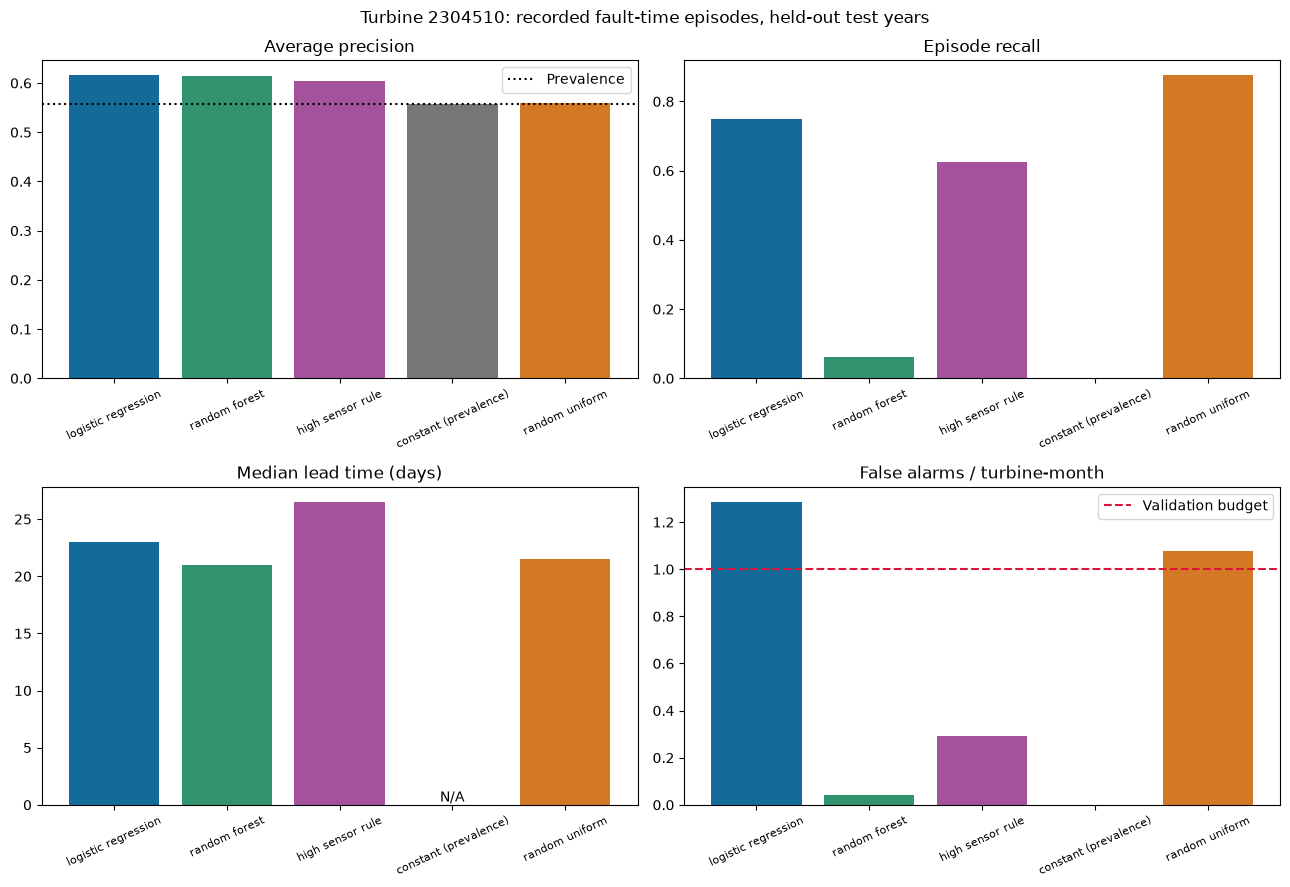

In [9]:
COLORS = {"logistic regression": "#146b9a", "random forest": "#32936f",
          "high sensor rule": "#a3529b", "constant (prevalence)": "#777777", "random uniform": "#d37824"}

def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric, title in zip(
    axes.flat,
    ("pr_auc", "recall", "median_lead_days", "false_alarms_per_turbine_month"),
    ("Average precision", "Episode recall", "Median lead time (days)", "False alarms / turbine-month"),
):
    ax.bar(overall["model"], overall[metric], color=[COLORS[m] for m in overall["model"]])
    for index, value in enumerate(overall[metric]):
        if pd.isna(value): ax.text(index, 0, "N/A", ha="center", va="bottom")
    ax.tick_params(axis="x", labelrotation=25, labelsize=8)
    if metric == "pr_auc":
        ax.axhline(overall["prevalence"].iloc[0], color="black", ls=":", label="Prevalence")
        ax.legend()
    if metric == "false_alarms_per_turbine_month":
        ax.axhline(cfg["evaluation"]["false_alarm_budget_per_turbine_month"],
                   color="crimson", ls="--", label="Validation budget")
        ax.legend()
    ax.set_title(title)
fig.suptitle(f"Turbine {STATION}: recorded fault-time episodes, held-out test years")
finish_figure(fig, "model_comparison.png")

### Precision–recall, alert tradeoffs, and confusion matrices
The threshold sweeps below describe test behaviour. Do not use them to choose a new threshold and then report that same test data as untouched.

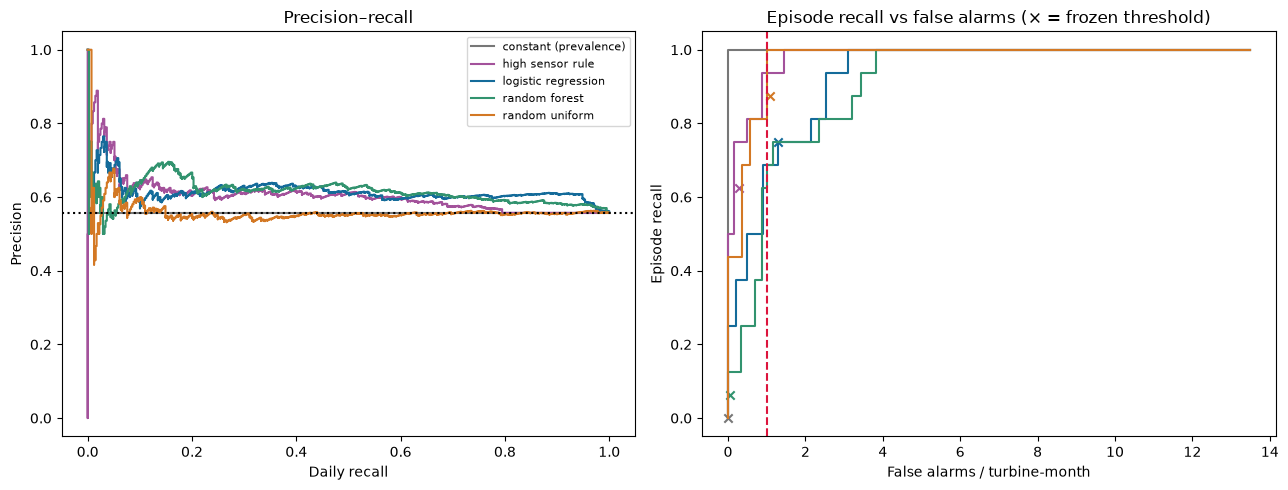

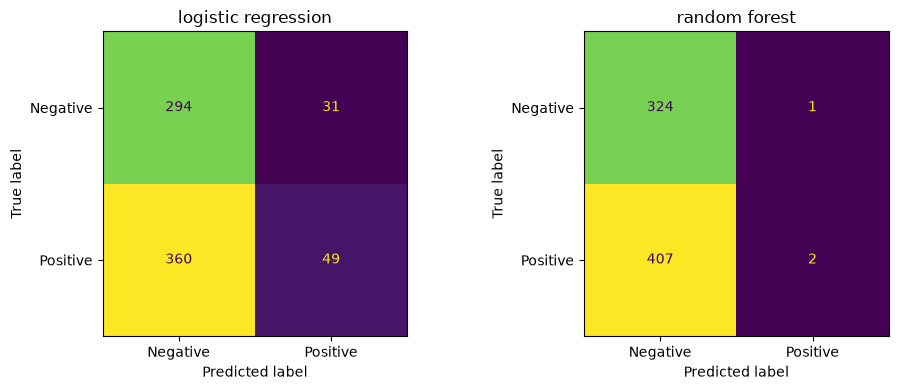

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, frame in predictions.groupby("model"):
    if frame["label"].sum():
        precision, recall, _ = precision_recall_curve(frame["label"], frame["score"])
        axes[0].step(recall, precision, where="post", label=name, color=COLORS[name])
    values = np.unique(np.r_[-np.inf, np.quantile(frame["score"], np.linspace(0, 1, 41))])
    points = [evaluate(frame, episodes, value, cfg) for value in values]
    axes[1].step([p["false_alarms_per_turbine_month"] for p in points],
                 [p["recall"] for p in points], where="post", color=COLORS[name])
    chosen = overall.loc[overall["model"].eq(name)].iloc[0]
    axes[1].scatter(chosen["false_alarms_per_turbine_month"], chosen["recall"], marker="x", color=COLORS[name])
axes[0].axhline(overall["prevalence"].iloc[0], color="black", ls=":")
axes[0].set(title="Precision–recall", xlabel="Daily recall", ylabel="Precision")
axes[0].legend(fontsize=8)
axes[1].axvline(cfg["evaluation"]["false_alarm_budget_per_turbine_month"], color="crimson", ls="--")
axes[1].set(title="Episode recall vs false alarms (× = frozen threshold)",
            xlabel="False alarms / turbine-month", ylabel="Episode recall")
finish_figure(fig, "threshold_curves.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, models):
    frame = predictions.loc[predictions["model"].eq(name)]
    ConfusionMatrixDisplay.from_predictions(frame["label"], frame["alert"].astype(int),
        labels=[0, 1], display_labels=["Negative", "Positive"], colorbar=False, ax=ax)
    ax.set_title(name)
finish_figure(fig, "confusion_matrices.png")

### Risk scores over time
Choose a held-out year and classifier below. Gaps are unscored/excluded days. Green lines mark episode starts; shaded regions are their preceding warning windows, not fault durations. Model scores are rankings, not established probabilities.

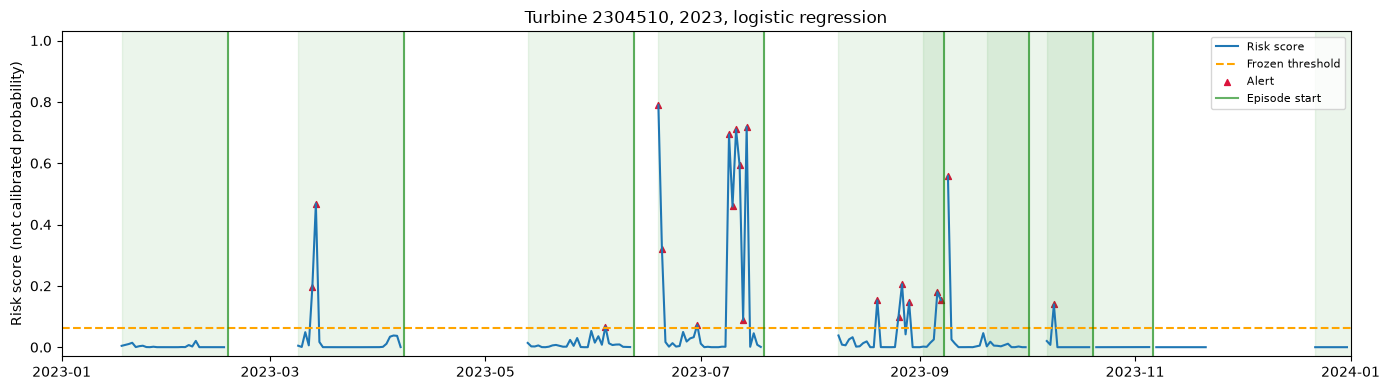

In [11]:
PLOT_YEAR = cfg["splits"]["test_years"][0]
PLOT_MODEL = "logistic regression"  # Or "random forest".
frame = predictions.loc[predictions["model"].eq(PLOT_MODEL) & predictions["Day"].dt.year.eq(PLOT_YEAR)]
series = frame.set_index("Day")["score"].reindex(pd.date_range(f"{PLOT_YEAR}-01-01", f"{PLOT_YEAR}-12-31"))
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(series.index, series.values, label="Risk score")
threshold = thresholds[PLOT_MODEL]
if np.isfinite(threshold): ax.axhline(threshold, ls="--", color="orange", label="Frozen threshold")
alerts = frame.loc[frame["alert"]]
ax.scatter(alerts["Day"], alerts["score"], marker="^", color="crimson", s=18, label="Alert")
warning_days = int(cfg["labels"]["positive_window_days"])
start = pd.Timestamp(f"{PLOT_YEAR}-01-01")
end = pd.Timestamp(f"{PLOT_YEAR+1}-01-01")
for i, episode_start in enumerate(episodes.loc[
    (episodes["Start"] >= start) & (episodes["Start"] < end + pd.Timedelta(days=warning_days)), "Start"
]):
    ax.axvline(episode_start, color="green", alpha=0.6, label="Episode start" if i == 0 else None)
    ax.axvspan(episode_start-pd.Timedelta(days=warning_days), episode_start, color="green", alpha=0.08)
ax.set(xlim=(start, end), ylim=(-0.03, 1.03), ylabel="Risk score (not calibrated probability)",
       title=f"Turbine {STATION}, {PLOT_YEAR}, {PLOT_MODEL}")
ax.legend(fontsize=8)
finish_figure(fig, f"{PLOT_YEAR}_timeline.png")

### Features and warning lead times
Logistic coefficients describe standardized input associations, not causes. Forest impurity importances are also affected by correlated inputs. Lead times below omit undetected episodes, so inspect episode recall alongside them.

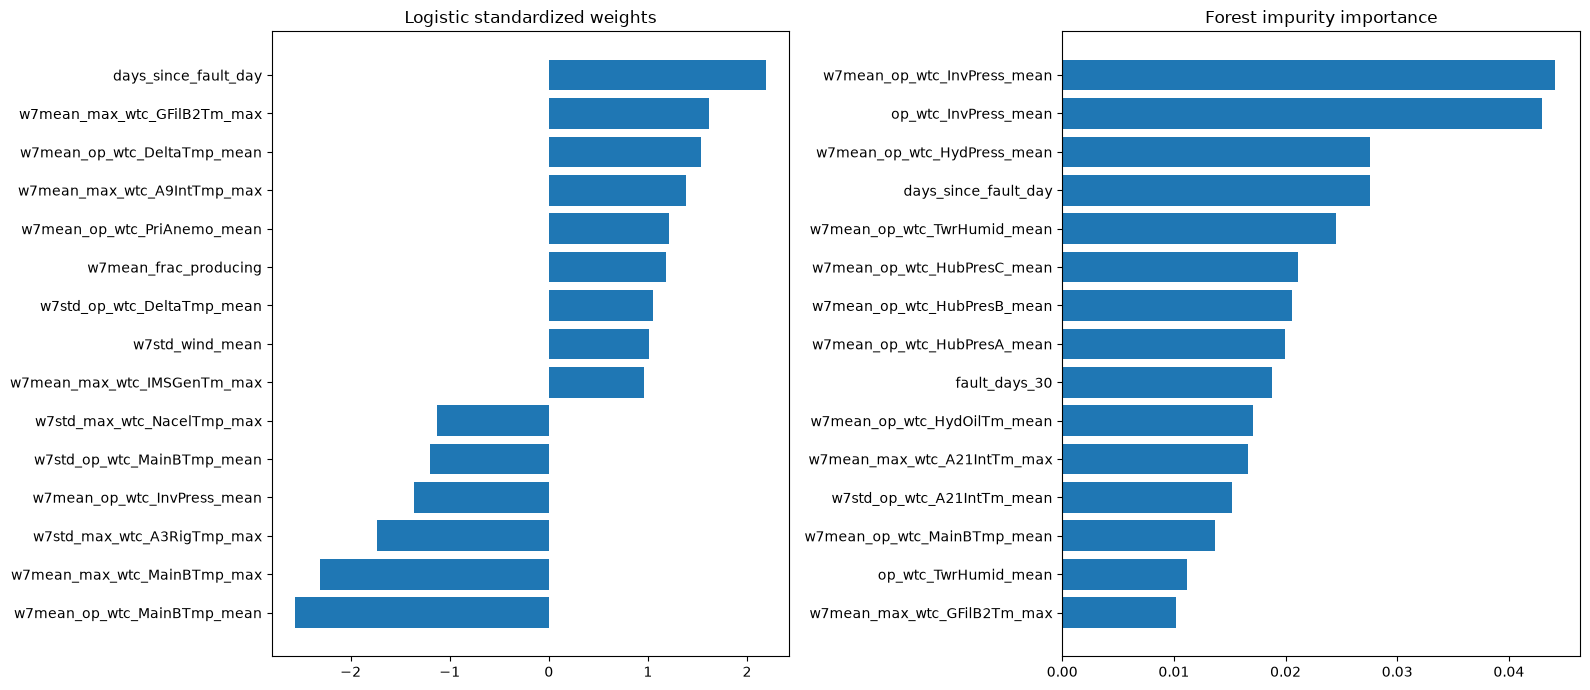

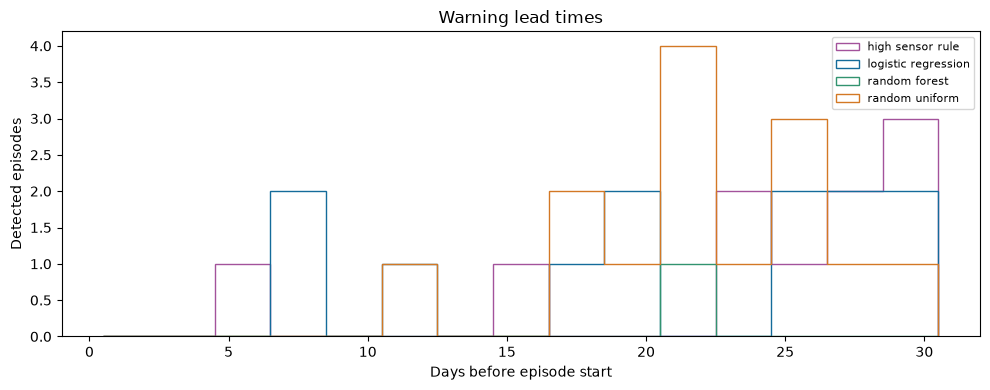

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, column, title in zip(axes, ("coefficient", "forest_importance"),
                            ("Logistic standardized weights", "Forest impurity importance")):
    used = feature_audit.dropna(subset=[column])
    top = used.loc[used[column].abs().nlargest(15).index].sort_values(column)
    ax.barh(top["feature"], top[column])
    ax.set_title(title)
finish_figure(fig, "feature_weights.png")

fig, ax = plt.subplots(figsize=(10, 4))
for name, group in detections.loc[detections["evaluable"] & detections["detected"]].groupby("model"):
    ax.hist(group["lead_days"], bins=np.arange(0.5, 31.6, 2), histtype="step", label=name, color=COLORS[name])
ax.set(xlabel="Days before episode start", ylabel="Detected episodes", title="Warning lead times")
if ax.patches: ax.legend(fontsize=8)
finish_figure(fig, "lead_times.png")

### Save the results
Everything saved here belongs only to the daily-fault-time target. No other target is trained, evaluated, or plotted.

The most useful files are **metrics.csv**, **predictions.csv**, and **features.csv**. All graphs above are also saved as PNGs. Rerunning replaces same-named notebook outputs.

Per-year episode counts can overlap at year boundaries; use the pooled test_all row for the overall result. Do not sum annual counts as distinct faults. These results concern one turbine, not transfer to other turbines. Refitting after inspecting test performance requires fresh held-out data for an unbiased new evaluation.

In [13]:
metrics.to_csv(RESULTS / "metrics.csv", index=False)
validation_metrics.to_csv(RESULTS / "validation_metrics.csv", index=False)
predictions.to_csv(RESULTS / "predictions.csv", index=False)
detections.to_csv(RESULTS / "episode_detections.csv", index=False)
feature_audit.to_csv(RESULTS / "features.csv", index=False)
coverage.to_csv(RESULTS / "coverage.csv", index=False)
for name, model in models.items():
    joblib.dump({"pipeline": model, "features": columns, "threshold": thresholds[name],
                 "station": STATION, "target": "A", "protocol": cfg},
                RESULTS / f"{name.replace(' ', '_')}.joblib")
joblib.dump({"sensor_rule": rule, "threshold": thresholds["high sensor rule"], "target": "A"},
            RESULTS / "high_sensor_rule.joblib")
(RESULTS / "run.json").write_text(json.dumps({
    "station": STATION, "target": "A", "protocol": cfg, "seed": SEED,
    "thresholds": {name: str(value) if not np.isfinite(value) else float(value)
                   for name, value in thresholds.items()},
    "training_features": columns, "max_missing": MAX_MISSING,
    "source": "notebooks/01_single_turbine_fault_prediction.ipynb",
}, indent=2), encoding="utf-8")
print("Saved results:", RESULTS)
print("Saved plots:", FIGURES)

Saved results: C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7\data\processed\multi_year\2018_2025\turbine_2304510\target_a_notebook
Saved plots: C:\Users\parve\Desktop\University Stuff\ENG2112\Project\ENGG2112-T3-G7\reports\figures\multi_year\2018_2025\turbine_2304510\target_a_notebook
